# 02 · Training: Multi-Horizon Fire Risk Model

**Purpose:** split the labelled data, build the preprocessing + model pipeline, compare candidate models and label strategies with 5-fold cross-validation **on the official competition metric**, tune the best one, and save it.

**Inputs:** `data/processed/train_clean.csv` (from notebook 01).

**Outputs:**
- `data/test/test_set.csv`: held-out 15% test split, **not used again until notebook 03**
- `data/processed/dev_set.csv`: the 85% development split
- `models/fire_risk_model.joblib`: the final fitted pipeline bundle
- `reports/figures/02_*.png` and `reports/cv_results.csv`

**Competition metric (what we optimise):**

$$\text{Hybrid} = 0.3 \times \text{C-index} + 0.7 \times (1 - \text{Weighted Brier})$$
$$\text{Weighted Brier} = 0.3\,\text{Brier@24h} + 0.4\,\text{Brier@48h} + 0.3\,\text{Brier@72h}$$

Each Brier@H is **censor-aware**:
- a hit counts as 1 if it happened by H, else 0
- a fire censored after H counts as 0
- a fire censored at or before H is **excluded**

The C-index ranks fires by urgency. We use the mean of the four horizon probabilities as the urgency score (see `src/model.py: risk_score`).

**Model:** one binary classifier per horizon (12, 24, 48 and 72 h after t0+5h), with probabilities forced to be non-decreasing across horizons.

## Setup

In [1]:
import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")  # so parallel workers can import src

from src.data import feature_columns, censor_aware_labels, HORIZONS, ID_COL, TIME_COL, EVENT_COL, TARGET_COLS
from src.model import MultiHorizonRiskModel, make_pipeline, SCORING, horizon_scores, HEADLINE_HORIZON

DATA_DIR = ROOT / "data"
PROC_DIR, TEST_DIR, MODEL_DIR = DATA_DIR / "processed", DATA_DIR / "test", ROOT / "models"
FIG_DIR, REPORT_DIR = ROOT / "reports" / "figures", ROOT / "reports"
for d in (TEST_DIR, MODEL_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Train / test split (85 / 15, stratified)
We use **85% development / 15% test**, with 5-fold CV on the development part instead of a separate 15% validation set. With 221 rows, a 33-row validation set would make model selection close to random.

We stratify on a 3-level key (*censored*, *hit after 12 h*, *hit within 12 h*), so every split contains both early and late hits.

In [2]:
df = pd.read_csv(PROC_DIR / "train_clean.csv")
FEATURES = feature_columns(df.drop(columns=[c for c in df.columns if c.startswith("hit_")]))
early = ((df[EVENT_COL] == 1) & (df[TIME_COL] <= 12)).astype(int)
strata = df[EVENT_COL] + early          # 0 = censored, 1 = late hit, 2 = early hit

dev, test = train_test_split(df, test_size=0.15, stratify=strata, random_state=RANDOM_STATE)
dev, test = dev.reset_index(drop=True), test.reset_index(drop=True)

raw_cols = [ID_COL] + FEATURES + TARGET_COLS
test[raw_cols].to_csv(TEST_DIR / "test_set.csv", index=False)   # untouched until notebook 03
dev[raw_cols].to_csv(PROC_DIR / "dev_set.csv", index=False)

def label_summary(part):
    lab = censor_aware_labels(part[TIME_COL], part[EVENT_COL])
    return pd.DataFrame({"positive": (lab == 1).sum(), "negative": (lab == 0).sum(), "excluded": lab.isna().sum()}).T
print(f"{len(FEATURES)} features | dev {len(dev)} rows | test {len(test)} rows")
pd.concat({"dev": label_summary(dev), "test": label_summary(test)})

34 features | dev 187 rows | test 34 rows


hit_12h  hit_24h  hit_48h  hit_72h
dev  positive       41       53       55       58
     negative      141      116       87        0
     excluded        5       18       45      129
test positive        8       10       11       11
     negative       25       17       13        0
     excluded        1        7       10       23

This table shows the censor-aware label counts per horizon. **At 72 h every evaluable fire is a hit.** All censored fires were last observed before 72 h (max 67 h), so the metric excludes them all at 72 h. Brier@72h therefore only rewards giving high probabilities to fires that do hit. The test file is now on disk and is **not read again in this notebook**.

In [3]:
X_dev = dev[FEATURES]
y_dev = dev[TARGET_COLS].to_numpy()          # [time_to_hit_hours, event]
strata_dev = (dev[EVENT_COL] + ((dev[EVENT_COL] == 1) & (dev[TIME_COL] <= 12))).to_numpy()
cv_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_dev, strata_dev))
print("fold sizes (validation):", [len(v) for _, v in cv_splits])

fold sizes (validation): [38, 38, 37, 37, 37]


## 2. Pipeline
Each horizon model is the same sklearn `Pipeline`:

1. `FeatureEngineer`: adds `log_dist_min`, `dist_minus_radius_km`, `within_10km`, `eta_hours`, `has_growth` and sin/cos encodings of hour and month (see `src/features.py`)
2. `ColumnTransformer`: numeric → `SimpleImputer(median)` → `StandardScaler`. Categorical → `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")` (the categorical branch is empty for this data).
3. the classifier

`MultiHorizonRiskModel` clones the pipeline for each horizon and enforces P(12h) ≤ P(24h) ≤ P(48h) ≤ P(72h). It supports two **training-label strategies**:
- **`censor_aware`** (matches the metric): a fire censored before H is dropped from the H model. At 72 h only hits remain, so the 72 h "model" is the smoothed base rate c = (k+1)/(n+2) ≈ 0.98 plus a rank-preserving term, c + (1−c)·mean(P12, P24, P48). That keeps the 72 h column ordered by urgency, in case the grader's C-index ranks on it.
- **`metadata`**: censored fires are negatives at every horizon. This is the data dictionary's "never hit within 72 h" reading, and it uses all rows.

Every preprocessing step is fitted inside the CV folds, so nothing leaks from the validation folds.

In [4]:
example = make_pipeline(LogisticRegression(max_iter=5000))
for name, step in example.steps:
    print(f"{name:>9}: {type(step).__name__}")
for name, trans, _ in example.named_steps["prep"].transformers:
    print(f"{'':>11}{name}: " + " -> ".join(f"{type(s).__name__}({s.get_params().get('strategy', '')})".replace("()", "") for _, s in trans.steps))

 features: FeatureEngineer
     prep: ColumnTransformer
      clf: LogisticRegression
           num: SimpleImputer(median) -> StandardScaler
           cat: SimpleImputer(most_frequent) -> OneHotEncoder


## 3. Model comparison (5-fold CV, competition metric)
We compare three models × two label strategies, plus a `DummyClassifier(prior)` no-skill baseline.

**Primary metric: Hybrid score** (higher is better). We also report its two components and the per-horizon censor-aware Brier and ROC-AUC.

In [5]:
candidates = {
    "Baseline (prior)": DummyClassifier(strategy="prior"),
    "LogisticRegression": LogisticRegression(max_iter=5000),
    "RandomForest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
per_h = {f"brier_{h}h": (lambda h: lambda m, X, y: -horizon_scores(m, X, y)[f"brier_{h}h"])(h) for h in (24, 48, 72)}
per_h |= {f"auc_{h}h": (lambda h: lambda m, X, y: horizon_scores(m, X, y)[f"auc_{h}h"])(h) for h in (12, 24, 48)}
scoring = SCORING | per_h

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, clf in candidates.items():
        for mode in ("censor_aware", "metadata"):
            est = MultiHorizonRiskModel(make_pipeline(clf), label_mode=mode)
            res = cross_validate(est, X_dev, y_dev, cv=cv_splits, scoring=scoring, n_jobs=-1)
            row = {"model": name, "label_mode": mode}
            for k in scoring:
                v = res[f"test_{k}"] * (-1 if k.startswith(("neg_", "brier_")) else 1)
                key = k.replace("neg_", "")
                row[f"{key}_mean"], row[f"{key}_std"] = np.nanmean(v), np.nanstd(v)
            rows.append(row)
cv_table = pd.DataFrame(rows).set_index(["model", "label_mode"]).sort_values("hybrid_mean", ascending=False)
cv_table.to_csv(REPORT_DIR / "cv_results.csv")
show = ["hybrid_mean", "hybrid_std", "weighted_brier_mean", "c_index_mean", "brier_24h_mean", "brier_48h_mean", "brier_72h_mean", "auc_12h_mean", "auc_24h_mean", "auc_48h_mean"]
cv_table[show].round(4)

hybrid_mean  hybrid_std  weighted_brier_mean  \
model              label_mode                                                   
RandomForest       censor_aware       0.9735      0.0082               0.0185   
                   metadata           0.9728      0.0065               0.0181   
GradientBoosting   metadata           0.9686      0.0107               0.0207   
                   censor_aware       0.9684      0.0089               0.0204   
LogisticRegression censor_aware       0.9384      0.0286               0.0500   
                   metadata           0.9288      0.0297               0.0636   
Baseline (prior)   censor_aware       0.7381      0.0026               0.1599   
                   metadata           0.6356      0.0048               0.3063   

                                 c_index_mean  brier_24h_mean  brier_48h_mean  \
model              label_mode                                                   
RandomForest       censor_aware        0.9546          0.0312          0.0228   
                   metadata            0.9516          0.0298          0.0201   
GradientBoosting   metadata            0.9434          0.0357          0.0249   
                   censor_aware        0.9421          0.0369          0.0233   
LogisticRegression censor_aware        0.9112          0.0793          0.0654   
                   metadata            0.9109          0.0802          0.0657   
Baseline (prior)   censor_aware        0.5000          0.2154          0.2380   
                   metadata            0.5000          0.2163          0.2465   

                                 brier_72h_mean  auc_12h_mean  auc_24h_mean  \
model              label_mode                                                 
RandomForest       censor_aware          0.0000        0.9685        0.9901   
                   metadata              0.0038        0.9712        0.9901   
GradientBoosting   metadata              0.0000        0.9632        0.9884   
                   censor_aware          0.0000        0.9614        0.9884   
LogisticRegression censor_aware          0.0001        0.9353        0.9580   
                   metadata              0.0442        0.9376        0.9546   
Baseline (prior)   censor_aware          0.0002        0.5000        0.5000   
                   metadata              0.4759        0.5000        0.5000   

                                 auc_48h_mean  
model              label_mode                  
RandomForest       censor_aware        0.9990  
                   metadata            0.9990  
GradientBoosting   metadata            0.9943  
                   censor_aware        0.9943  
LogisticRegression censor_aware        0.9708  
                   metadata            0.9705  
Baseline (prior)   censor_aware        0.5000  
                   metadata            0.5000

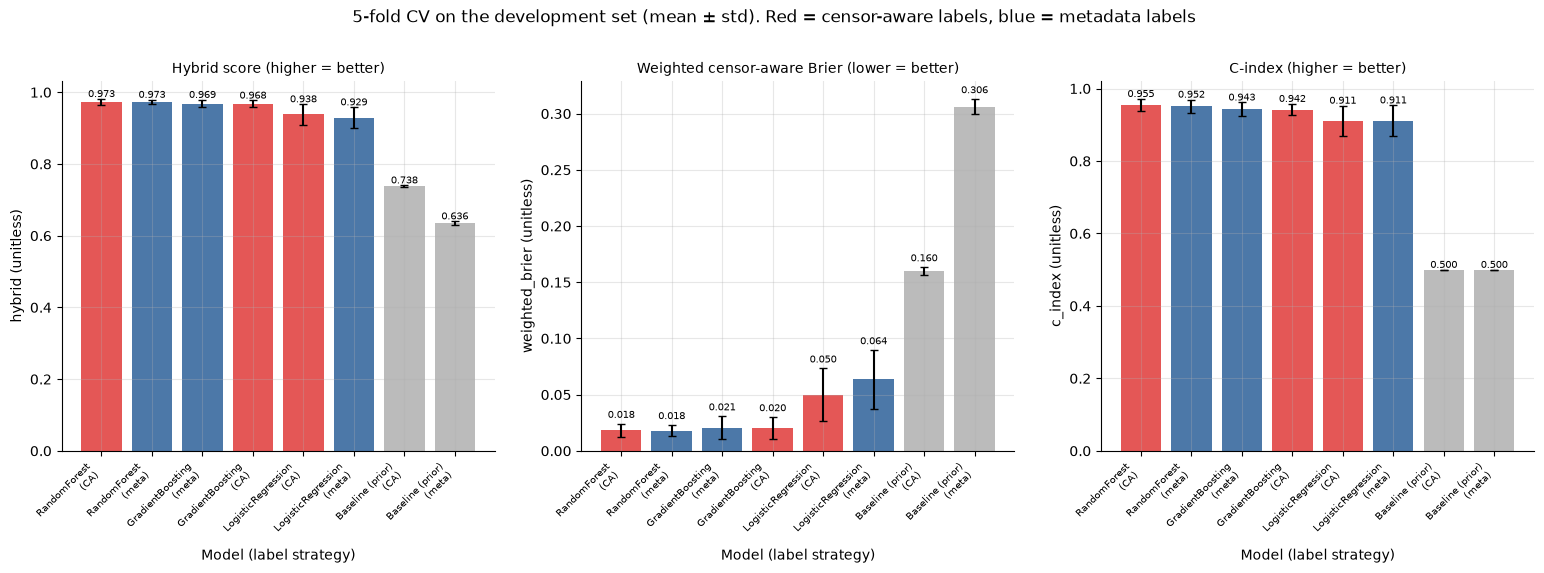

In [6]:
labels_ = [f"{m}\n({'CA' if l == 'censor_aware' else 'meta'})" for m, l in cv_table.index]
colors = ["#BBBBBB" if "Baseline" in m else ("#E45756" if l == "censor_aware" else "#4C78A8") for m, l in cv_table.index]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (metric, label) in zip(axes, [("hybrid", "Hybrid score (higher = better)"),
                                       ("weighted_brier", "Weighted censor-aware Brier (lower = better)"),
                                       ("c_index", "C-index (higher = better)")]):
    m, s = cv_table[f"{metric}_mean"], cv_table[f"{metric}_std"]
    ax.bar(range(len(m)), m, yerr=s, capsize=3, color=colors)
    for i, v in enumerate(m): ax.text(i, v + s.iloc[i] + 0.005, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks(range(len(m)), labels_, rotation=45, ha="right", fontsize=7)
    ax.set_title(label, fontsize=10); ax.set_ylabel(metric + " (unitless)"); ax.set_xlabel("Model (label strategy)")
fig.suptitle("5-fold CV on the development set (mean ± std). Red = censor-aware labels, blue = metadata labels", y=1.03)
save(fig, "02_cv_model_comparison"); plt.show()

## 4. Hyper-parameter tuning (`GridSearchCV`, refit on Hybrid)
We tune the best model family + label strategy from the comparison, using the same 5 folds and `refit="hybrid"`. The grids are kept small because 187 rows cannot support a fine search without overfitting the CV.

In [7]:
ranked = cv_table.drop(index="Baseline (prior)", level=0)
best_family, best_mode = ranked["hybrid_mean"].idxmax()
grids = {
    "LogisticRegression": {"estimator__clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "RandomForest": {"estimator__clf__n_estimators": [500],
                     "estimator__clf__max_depth": [None, 4, 8],
                     "estimator__clf__min_samples_leaf": [1, 3, 5, 10],
                     "estimator__clf__max_features": ["sqrt", 0.5]},
    "GradientBoosting": {"estimator__clf__n_estimators": [50, 100, 200],
                         "estimator__clf__learning_rate": [0.03, 0.1],
                         "estimator__clf__max_depth": [2, 3],
                         "estimator__clf__subsample": [0.7, 1.0],
                         "estimator__clf__min_samples_leaf": [3, 10]},
}
print(f"Tuning: {best_family} with label_mode={best_mode} | grid size:", int(np.prod([len(v) for v in grids[best_family].values()])))
search = GridSearchCV(MultiHorizonRiskModel(make_pipeline(candidates[best_family]), label_mode=best_mode), grids[best_family],
                      scoring=SCORING, refit="hybrid", cv=cv_splits, n_jobs=-1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    search.fit(X_dev, y_dev)

res = pd.DataFrame(search.cv_results_)
res["weighted_brier"] = -res["mean_test_neg_weighted_brier"]
top = res.sort_values("mean_test_hybrid", ascending=False)[["params", "mean_test_hybrid", "std_test_hybrid", "weighted_brier", "mean_test_c_index"]].head(10)
top["params"] = top["params"].apply(lambda p: {k.replace("estimator__clf__", ""): v for k, v in p.items()})
print("best params:", top.iloc[0]["params"])
top.round(4)

Tuning: RandomForest with label_mode=censor_aware | grid size: 24


best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 500}


,params,mean_test_hybrid,std_test_hybrid,weighted_brier,mean_test_c_index
6,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.9756,0.0054,0.0145,0.9527
22,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.9756,0.0054,0.0145,0.9527
14,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.9755,0.0051,0.0145,0.9520
13,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.9753,0.0053,0.0145,0.9515
21,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.9748,0.0056,0.0145,0.9498
5,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.9748,0.0056,0.0145,0.9498
12,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.9745,0.0051,0.0154,0.9509
7,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.9738,0.0064,0.0163,0.9508
15,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",0.9738,0.0064,0.0163,0.9508
23,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",0.9738,0.0064,0.0163,0.9508


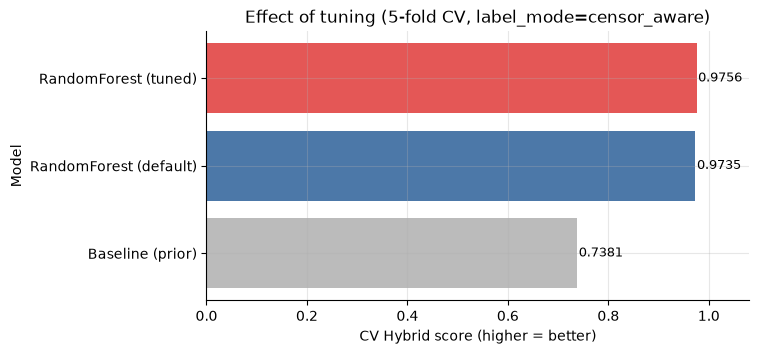

,hybrid,weighted_brier,c_index
Baseline (prior),0.7381,0.1599,0.5000
RandomForest (default),0.9735,0.0185,0.9546
RandomForest (tuned),0.9756,0.0145,0.9527


In [8]:
tuned = res.loc[search.best_index_]
base = cv_table.loc[("Baseline (prior)", best_mode)]
default = cv_table.loc[(best_family, best_mode)]
compare = pd.DataFrame({
    "hybrid": [base["hybrid_mean"], default["hybrid_mean"], tuned["mean_test_hybrid"]],
    "weighted_brier": [base["weighted_brier_mean"], default["weighted_brier_mean"], tuned["weighted_brier"]],
    "c_index": [base["c_index_mean"], default["c_index_mean"], tuned["mean_test_c_index"]],
}, index=["Baseline (prior)", f"{best_family} (default)", f"{best_family} (tuned)"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(compare.index, compare["hybrid"], color=["#BBBBBB", "#4C78A8", "#E45756"])
for i, v in enumerate(compare["hybrid"]): ax.text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel("CV Hybrid score (higher = better)"); ax.set_ylabel("Model"); ax.set_title(f"Effect of tuning (5-fold CV, label_mode={best_mode})")
save(fig, "02_tuning_effect"); plt.show()
compare.round(4)

## 5. Save the final model
The `GridSearchCV` refit already trained the best configuration on the whole development set. We save it with joblib, together with the feature list and the training metadata `src/predict.py` needs.

In [9]:
final_model = search.best_estimator_
bundle = {
    "model": final_model,
    "feature_columns": FEATURES,
    "horizons": list(HORIZONS),
    "headline_horizon": HEADLINE_HORIZON,
    "model_family": best_family,
    "label_mode": best_mode,
    "best_params": {k.replace("estimator__clf__", ""): v for k, v in search.best_params_.items()},
    "cv_hybrid": float(tuned["mean_test_hybrid"]),
    "cv_weighted_brier": float(tuned["weighted_brier"]),
    "cv_c_index": float(tuned["mean_test_c_index"]),
    "n_train_rows": int(len(X_dev)),
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
}
joblib.dump(bundle, MODEL_DIR / "fire_risk_model.joblib")
print("saved", (MODEL_DIR / "fire_risk_model.joblib").relative_to(ROOT), "|", {k: v for k, v in bundle.items() if k not in ("model", "feature_columns")})

saved models/fire_risk_model.joblib | {'horizons': [12, 24, 48, 72], 'headline_horizon': 48, 'model_family': 'RandomForest', 'label_mode': 'censor_aware', 'best_params': {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 500}, 'cv_hybrid': 0.9756353350100282, 'cv_weighted_brier': 0.014516704864183067, 'cv_c_index': 0.952656761383188, 'n_train_rows': 187, 'sklearn_version': '1.9.1', 'random_state': 42}


## 6. Training Summary
| Model (5-fold CV, dev n=187) | Labels | Hybrid ↑ | Weighted Brier ↓ | C-index ↑ |
|---|---|---|---|---|
| Baseline (prior) | censor-aware | 0.7381 | 0.1599 | 0.5000 |
| LogisticRegression | censor-aware | 0.9384 | 0.0500 | 0.9112 |
| GradientBoosting | metadata | 0.9686 | 0.0207 | 0.9434 |
| RandomForest (default) | metadata | 0.9728 | 0.0181 | 0.9516 |
| RandomForest (default) | censor-aware | 0.9735 | 0.0185 | 0.9546 |
| **RandomForest (tuned)** | **censor-aware** | **0.9756** | **0.0145** | **0.9527** |

- **Tree ensembles clearly beat logistic regression.** The key signal is a sharp distance threshold combined with zero-inflated, skewed features.
- **Label strategy barely matters for the score** (0.9735 vs 0.9728, well within one fold standard deviation). Censor-aware labels win on C-index and Brier@72h. Metadata labels are slightly better at 24 h and 48 h, because they keep censored rows as extra negatives. We keep **censor-aware labels because they match the metric.**
- **One consequence at 72 h:** every evaluable training fire is a hit, so the 72 h output is about 98–100% for every fire. That is optimal for Brier@72h but not a meaningful operational risk for a fire 300 km away. This is why the CLI's headline `risk_percentage` is the **48 h** risk, which is also the horizon the competition weights most.
- **The tuned model** is a Random Forest with 500 trees, `max_features=0.5` and `min_samples_leaf=5`. Its CV Hybrid score is **0.9756**. The top configurations lie within about 0.002 of each other, so the choice is stable.
- These are CV estimates. The untouched 34-row test set is evaluated in notebook 03.